# TAHAP 6: ANALISIS SPASIAL PCA TERPADU (UNIFIED COORDINATE SPACE)
### Proyeksi Sebaran Varian WGS Jawa Barat terhadap Peta Referensi ClinVar


## 1. IMPORT SELURUH LIBRARY


In [ ]:
import os #untuk berinteraksi dengan os/cek file
import shutil #copy, move, & backup file
from pathlib import Path #manajemen path file/folder

import matplotlib.pyplot as plt #kanvas grafik
import numpy as np #operasi matematika
import pandas as pd #mengelola tabel

from google.colab import drive #menyambungkan ke drive
from sklearn.decomposition import PCA #mereduksi dimensi
from sklearn.impute import SimpleImputer #mengisi datakosong dengan median
from sklearn.preprocessing import StandardScaler #menyetarakan skala nilai

## 2. MOUNT GOOGLE DRIVE


In [ ]:
if not os.path.ismount('/content/drive'):
    print("Membersihkan folder dummy lokal...")
    !rm -rf /content/drive
    print("Menghubungkan Google Drive yang asli...")
    drive.mount('/content/drive')
else:
    print("Google Drive sudah terhubung!")

BASE_DIR = Path('/content/drive/MyDrive/skripsi/data')
LAMPIRAN_DIR = BASE_DIR / 'Lampiran_Skripsi'
LAMPIRAN_DIR.mkdir(parents=True, exist_ok=True)

Membersihkan folder dummy lokal...
Menghubungkan Google Drive yang asli...
Mounted at /content/drive


## 3. MEMUAT DATASET WGS JAWA BARAT & CLINVAR


In [ ]:
# Memuat Data Hasil Prediksi WGS Jawa Barat
wgs_path = BASE_DIR / 'WGS_JawaBarat_Clean_Predicted.csv'
clinvar_path = BASE_DIR / 'clinvar_dbnsfp_merged.csv'

print(f"\n1. Membaca data WGS: {wgs_path.name} ...")
df_wgs = pd.read_csv(wgs_path)
print(f"   -> Terbaca: {len(df_wgs):,} varian novel WGS.")

print(f"\n2. Membaca data ClinVar: {clinvar_path.name} ...")
# Memuat Data ClinVar Secara Hemat Memori (RAM)
features = ['CADD', 'SIFT', 'PolyPhen', 'MAF', 'REVEL', 'MetaSVM', 'PhyloP']
use_cols = ['label'] + features
df_clinvar = pd.read_csv(clinvar_path, usecols=lambda c: c in use_cols)
# Menyederhanakan & Menyaring Label ClinVar Menjadi 2 Kelas (Biner)
df_clinvar['label'] = df_clinvar['label'].replace({
    'Likely benign': 'Benign',
    'Likely pathogenic': 'Pathogenic'
})

df_clinvar = df_clinvar[df_clinvar['label'].isin(['Benign', 'Pathogenic'])].copy()
print(f"   -> Terbaca: {len(df_clinvar):,} varian ClinVar valid.")
# Menyamakan Nama Kolom Identitas untuk Visualisasi Gabungan
df_clinvar['Sumber'] = 'ClinVar (Referensi)'
df_clinvar['Status'] = df_clinvar['label']

df_wgs['Sumber'] = 'WGS Jabar (Prediksi Novel)'
df_wgs['Status'] = df_wgs['Predicted_Class']


1. Membaca data WGS: WGS_JawaBarat_Clean_Predicted.csv ...
   -> Terbaca: 33,015 varian novel WGS.

2. Membaca data ClinVar: clinvar_dbnsfp_merged.csv ...
   -> Terbaca: 357,191 varian ClinVar valid.


## 4. PERHITUNGAN PCA TERPADU (DALAM 1 RUANG KOORDINAT)


In [ ]:
# Menyiapkan peta Acuan ClinVar
print("\nMenghitung PCA gabungan...")
# Menyiapkan Alat Pra-pemrosesan & Memisahkan Fitur
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
# Imputasi & Standarisasi Berbasis Acuan ClinVar
X_clinvar_raw = df_clinvar[features]
X_wgs_raw = df_wgs[features]

X_clinvar_imp = imputer.fit_transform(X_clinvar_raw)
X_wgs_imp = imputer.transform(X_wgs_raw)

X_clinvar_scaled = scaler.fit_transform(X_clinvar_imp)
X_wgs_scaled = scaler.transform(X_wgs_imp)
# Perhitungan Proyeksi PCA 2 Dimensi
pca = PCA(n_components=2, random_state=42)
pca_clinvar = pca.fit_transform(X_clinvar_scaled)
pca_wgs = pca.transform(X_wgs_scaled)
# Menyimpan Hasil Koordinat ke Tabel Masing-Masing
df_clinvar['PCA1'] = pca_clinvar[:, 0]
df_clinvar['PCA2'] = pca_clinvar[:, 1]

df_wgs['PCA1'] = pca_wgs[:, 0]
df_wgs['PCA2'] = pca_wgs[:, 1]
# Menghitung Persentase Informasi yang Berhasil Dipertahankan
var1 = pca.explained_variance_ratio_[0] * 100
var2 = pca.explained_variance_ratio_[1] * 100
print(f"PCA selesai! PC1: {var1:.1f}%, PC2: {var2:.1f}% (Total: {var1+var2:.1f}%)")


Menghitung PCA gabungan...
PCA selesai! PC1: 51.3%, PC2: 16.8% (Total: 68.0%)


## 5. VISUALISASI 1: OVERLAY GABUNGAN (KLINIS & ELEGAN)



Membuat Grafik 1: Overlay Gabungan ClinVar + WGS...


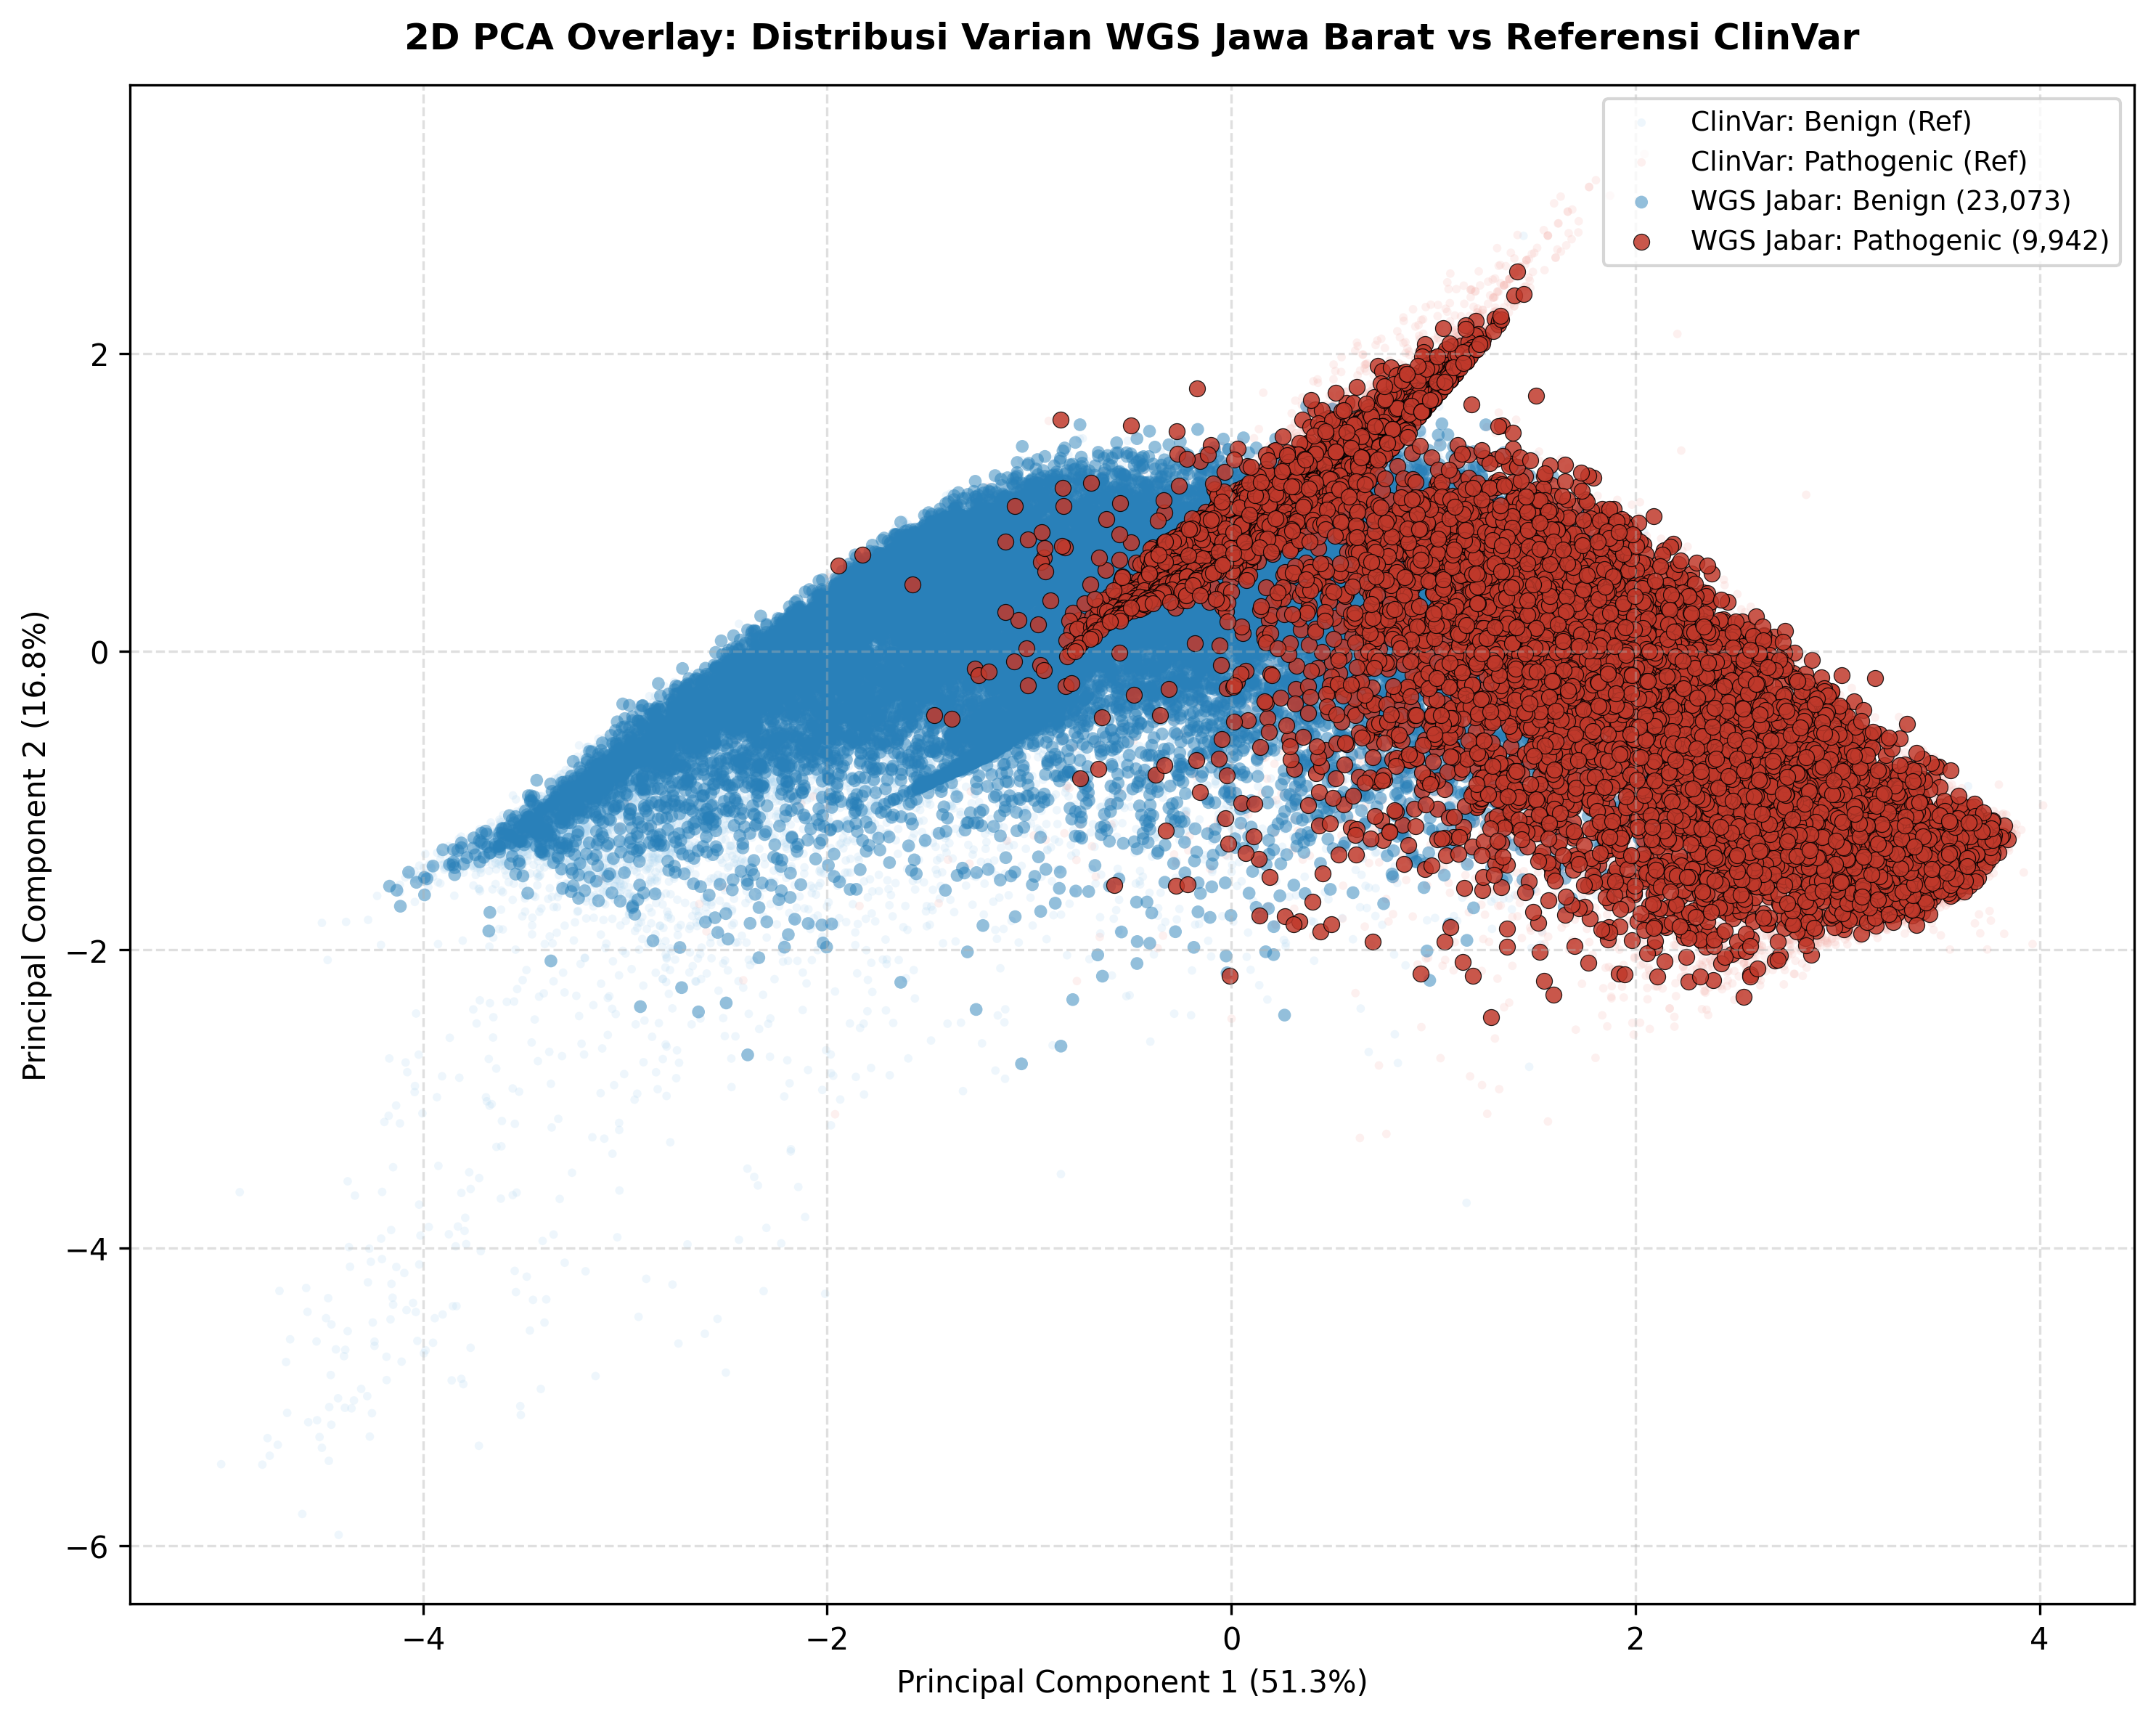

Grafik Overlay disimpan di: /content/drive/MyDrive/skripsi/data/Lampiran_Skripsi/pca_overlay_clinvar_vs_wgs.png


In [ ]:
print("\nMembuat Grafik 1: Overlay Gabungan ClinVar + WGS...")
plt.figure(figsize=(10, 8), dpi=300)
# Downsampling Data ClinVar Agar Grafik Tidak Berat
df_cv_sample = df_clinvar.sample(n=min(40000, len(df_clinvar)), random_state=42)
# Menggambar Lapisan Dasar (Latar Belakang): Referensi ClinVar
cv_benign = df_cv_sample[df_cv_sample['Status'] == 'Benign']
cv_patho = df_cv_sample[df_cv_sample['Status'] == 'Pathogenic']

plt.scatter(cv_benign['PCA1'], cv_benign['PCA2'], c='#aed6f1', label='ClinVar: Benign (Ref)', alpha=0.2, s=8, edgecolors='none')
plt.scatter(cv_patho['PCA1'], cv_patho['PCA2'], c='#f5b7b1', label='ClinVar: Pathogenic (Ref)', alpha=0.2, s=8, edgecolors='none')
# Menggambar Lapisan Atas (Foreground): Varian WGS Jawa Barat
wgs_benign = df_wgs[df_wgs['Status'] == 'Benign']
wgs_patho = df_wgs[df_wgs['Status'] == 'Pathogenic']

plt.scatter(wgs_benign['PCA1'], wgs_benign['PCA2'], c='#2980b9', label=f'WGS Jabar: Benign ({len(wgs_benign):,})', alpha=0.5, s=18, edgecolors='none')
plt.scatter(wgs_patho['PCA1'], wgs_patho['PCA2'], c='#c0392b', label=f'WGS Jabar: Pathogenic ({len(wgs_patho):,})', alpha=0.85, s=28, edgecolors='black', linewidths=0.3)
# Kosmetik Grafik & Penyimpanan File
plt.title('2D PCA Overlay: Distribusi Varian WGS Jawa Barat vs Referensi ClinVar', fontsize=12, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({var1:.1f}%)', fontsize=10)
plt.ylabel(f'Principal Component 2 ({var2:.1f}%)', fontsize=10)
plt.legend(loc='upper right', frameon=True, fontsize=9)
plt.grid(True, linestyle='--', alpha=0.4)

out_overlay = LAMPIRAN_DIR / 'pca_overlay_clinvar_vs_wgs.png'
plt.tight_layout()
plt.savefig(out_overlay, dpi=300)
plt.show()
print(f"Grafik Overlay disimpan di: {out_overlay}")

## 6. VISUALISASI 2: BERDAMPINGAN (SIDE-BY-SIDE COMPARISON)


In [ ]:
print("\nMembuat Grafik 2: Perbandingan Berdampingan (Side-by-Side)...")
# Membuat Kanvas Kembar dengan Sumbu Koordinat Terkunci
fig, axes = plt.subplots(1, 2, figsize=(16, 7), dpi=300, sharex=True, sharey=True)

palette = {'Benign': '#3498db', 'Pathogenic': '#e74c3c'}
# Menggambar Panel Kanan (axes[1]): Hasil Prediksi WGS Jawa Barat
for stat in ['Benign', 'Pathogenic']:
    sub = df_cv_sample[df_cv_sample['Status'] == stat]
    alpha_val = 0.25 if stat == 'Benign' else 0.4
    axes[0].scatter(sub['PCA1'], sub['PCA2'], c=palette[stat], label=f"{stat} ({len(df_clinvar[df_clinvar['Status']==stat]):,})", alpha=alpha_val, s=10, edgecolors='none')

axes[0].set_title('(A) Pangkalan Data Referensi Global (ClinVar NCBI)', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'Principal Component 1 ({var1:.1f}%)', fontsize=10)
axes[0].set_ylabel(f'Principal Component 2 ({var2:.1f}%)', fontsize=10)
axes[0].legend(title='Status Klinis Asli', loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.4)

for stat in ['Benign', 'Pathogenic']:
    sub = df_wgs[df_wgs['Status'] == stat]
    alpha_val = 0.3 if stat == 'Benign' else 0.85
    s_val = 15 if stat == 'Benign' else 32
    edge_val = 'none' if stat == 'Benign' else 'black'
    axes[1].scatter(sub['PCA1'], sub['PCA2'], c=palette[stat], label=f"{stat} ({len(sub):,})", alpha=alpha_val, s=s_val, edgecolors=edge_val, linewidths=0.3)

axes[1].set_title('(B) Hasil Skrining Varian Novel (WGS Jawa Barat)', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'Principal Component 1 ({var1:.1f}%)', fontsize=10)
axes[1].legend(title='Prediksi Model RF', loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.4)
# Penyimpanan Hasil Akhir
out_side = LAMPIRAN_DIR / 'pca_side_by_side_clinvar_vs_wgs.png'
plt.tight_layout()
plt.savefig(out_side, dpi=300)
plt.show()
print(f"Grafik Side-by-Side disimpan di: {out_side}")
print("\n[SELESAI] Seluruh komparasi PCA berhasil dibuat!")

Output hidden; open in https://colab.research.google.com to view.